# Лабораторна робота № 2. Побудова регресора методом k-найближчих сусідів (k-NN)

**Дисципліна:** Методи та системи штучного інтелекту

**Мета:** отримати навички аналізу даних з використанням регресора за методом k-найближчих сусідів.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
SEED = 42

## 1. Генерація випадкового набору даних (1000 значень)

Ознака $x$ — 1000 випадкових значень, рівномірно розподілених на відрізку [0; 10]. Цільова змінна — нелінійна функція з випадковим шумом:

$$y = 3\sin(x) + 0{,}5x + \varepsilon, \qquad \varepsilon \sim N(0;\ 0{,}8^2).$$

Нелінійна залежність обрана, щоб показати перевагу k-NN: метод не припускає певної форми функції.

Розмір набору: (1000, 2)
              x         y
count  1000.000  1000.000
mean      4.972     3.040
std       2.916     2.531
min       0.012    -2.692
25%       2.403     1.061
50%       4.948     3.111
75%       7.589     4.807
max       9.991     8.790


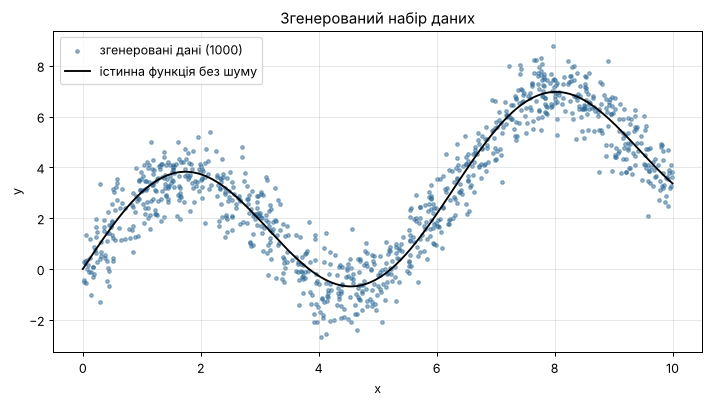

In [2]:
rng = np.random.default_rng(SEED)
N = 1000
x = rng.uniform(0, 10, N)
y_true = 3 * np.sin(x) + 0.5 * x
y = y_true + rng.normal(0, 0.8, N)

data = pd.DataFrame({"x": x, "y": y})
data.to_csv("knn_dataset.csv", index=False)
print("Розмір набору:", data.shape)
print(data.describe().round(3))

xs = np.linspace(0, 10, 500)
plt.figure(figsize=(8, 4.6))
plt.scatter(x, y, s=8, alpha=0.5, color="#2f6f9f", label="згенеровані дані (1000)")
plt.plot(xs, 3 * np.sin(xs) + 0.5 * xs, color="black", lw=1.5, label="істинна функція без шуму")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Згенерований набір даних"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "1_data.png", dpi=150); plt.show()

## 2. Нормалізація значень

Застосовано мінімаксну нормалізацію: $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$, що переводить значення ознаки та цільової змінної в діапазон [0; 1]. Для k-NN нормалізація важлива, бо метод спирається на відстані між об'єктами.

In [3]:
scaler_x, scaler_y = MinMaxScaler(), MinMaxScaler()
X_norm = scaler_x.fit_transform(data[["x"]])
y_norm = scaler_y.fit_transform(data[["y"]]).ravel()

norm_table = pd.DataFrame({"x": data["x"].head(5).round(3), "x′": X_norm[:5, 0].round(4),
                           "y": data["y"].head(5).round(3), "y′": y_norm[:5].round(4)})
print(norm_table.to_string())
print(f"\nДіапазон після нормалізації: x′ ∈ [{X_norm.min():.1f}; {X_norm.max():.1f}], "
      f"y′ ∈ [{y_norm.min():.1f}; {y_norm.max():.1f}]")

       x      x′      y      y′
0  7.740  0.7744  6.256  0.7794
1  4.389  0.4386  0.090  0.2423
2  8.586  0.8592  6.552  0.8051
3  6.974  0.6976  5.171  0.6849
4  0.942  0.0931  2.812  0.4793

Діапазон після нормалізації: x′ ∈ [0.0; 1.0], y′ ∈ [0.0; 1.0]


## 3. Розділення на навчальну і тестову вибірки

Навчальна вибірка: 800 записів, тестова: 200 записів


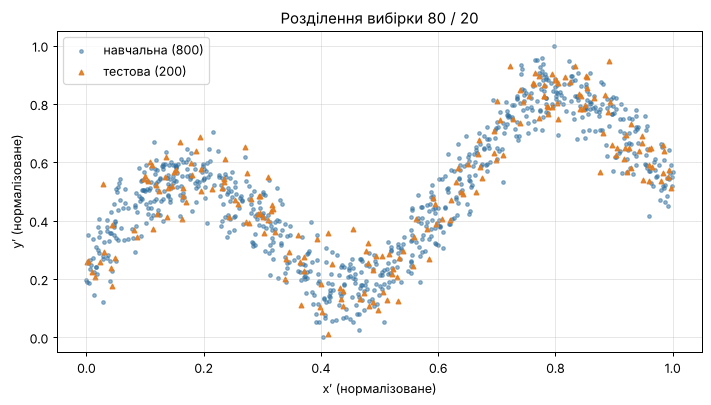

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X_norm, y_norm, test_size=0.2, random_state=SEED)
print(f"Навчальна вибірка: {len(X_train)} записів, тестова: {len(X_test)} записів")

plt.figure(figsize=(8, 4.6))
plt.scatter(X_train, y_train, s=8, alpha=0.5, color="#2f6f9f", label=f"навчальна ({len(X_train)})")
plt.scatter(X_test, y_test, s=14, alpha=0.9, color="#e07a1f", marker="^", label=f"тестова ({len(X_test)})")
plt.xlabel("x′ (нормалізоване)"); plt.ylabel("y′ (нормалізоване)")
plt.title("Розділення вибірки 80 / 20"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "3_split.png", dpi=150); plt.show()

## 4. Навчання KNN-регресора з різними значеннями K

In [5]:
def evaluate(k):
    model = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    p_tr, p_te = model.predict(X_train), model.predict(X_test)
    return {"K": k,
            "MSE train": mean_squared_error(y_train, p_tr),
            "MSE test": mean_squared_error(y_test, p_te),
            "RMSE test": np.sqrt(mean_squared_error(y_test, p_te)),
            "MAE test": mean_absolute_error(y_test, p_te),
            "R² test": r2_score(y_test, p_te)}

results = pd.DataFrame([evaluate(k) for k in range(1, 201)]).set_index("K")
print(results.loc[[1, 2, 3, 5, 10, 15, 20, 30, 50, 100, 150, 200]].round(5).to_string())

     MSE train  MSE test  RMSE test  MAE test  R² test
K                                                     
1      0.00000   0.00866    0.09306   0.07467  0.83119
2      0.00210   0.00733    0.08564   0.06792  0.85704
3      0.00290   0.00703    0.08385   0.06716  0.86293
5      0.00361   0.00630    0.07940   0.06258  0.87710
10     0.00403   0.00600    0.07746   0.06117  0.88303
15     0.00436   0.00610    0.07810   0.06241  0.88108
20     0.00443   0.00606    0.07787   0.06212  0.88181
30     0.00464   0.00603    0.07765   0.06159  0.88245
50     0.00478   0.00608    0.07794   0.06273  0.88158
100    0.00569   0.00704    0.08391   0.06810  0.86273
150    0.00738   0.00918    0.09582   0.07779  0.82103
200    0.00956   0.01179    0.10857   0.08901  0.77020


## 5. Вибір K з найкращими показниками якості на тестовій вибірці

Найкраще K = 11
MSE = 0.00598, RMSE = 0.07736, MAE = 0.06168, R² = 0.8834
K з найкращим R²: 11 | з найкращим MAE: 10
RMSE у вихідних одиницях y: 0.888 (стандартне відхилення шуму — 0.8)


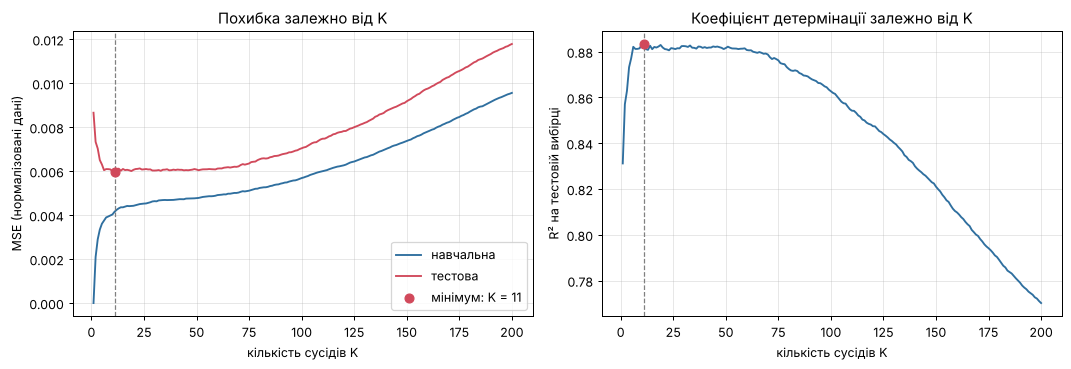

In [6]:
best_k = int(results["MSE test"].idxmin())
best = results.loc[best_k]
print(f"Найкраще K = {best_k}")
print(f"MSE = {best['MSE test']:.5f}, RMSE = {best['RMSE test']:.5f}, "
      f"MAE = {best['MAE test']:.5f}, R² = {best['R² test']:.4f}")
print("K з найкращим R²:", int(results["R² test"].idxmax()), "| з найкращим MAE:", int(results["MAE test"].idxmin()))

# Похибка у вихідних одиницях y
rmse_orig = best["RMSE test"] * (scaler_y.data_max_[0] - scaler_y.data_min_[0])
print(f"RMSE у вихідних одиницях y: {rmse_orig:.3f} (стандартне відхилення шуму — 0.8)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(results.index, results["MSE train"], color="#2f6f9f", label="навчальна")
axes[0].plot(results.index, results["MSE test"], color="#d1495b", label="тестова")
axes[0].axvline(best_k, color="gray", ls="--", lw=1)
axes[0].scatter([best_k], [best["MSE test"]], color="#d1495b", zorder=5, s=50, label=f"мінімум: K = {best_k}")
axes[0].set_xlabel("кількість сусідів K"); axes[0].set_ylabel("MSE (нормалізовані дані)")
axes[0].set_title("Похибка залежно від K"); axes[0].legend()
axes[1].plot(results.index, results["R² test"], color="#2f6f9f")
axes[1].scatter([best_k], [best["R² test"]], color="#d1495b", zorder=5, s=50)
axes[1].axvline(best_k, color="gray", ls="--", lw=1)
axes[1].set_xlabel("кількість сусідів K"); axes[1].set_ylabel("R² на тестовій вибірці")
axes[1].set_title("Коефіцієнт детермінації залежно від K")
plt.tight_layout(); plt.savefig(FIG / "5_k_curve.png", dpi=150); plt.show()

## 6. Візуалізація отриманих рішень

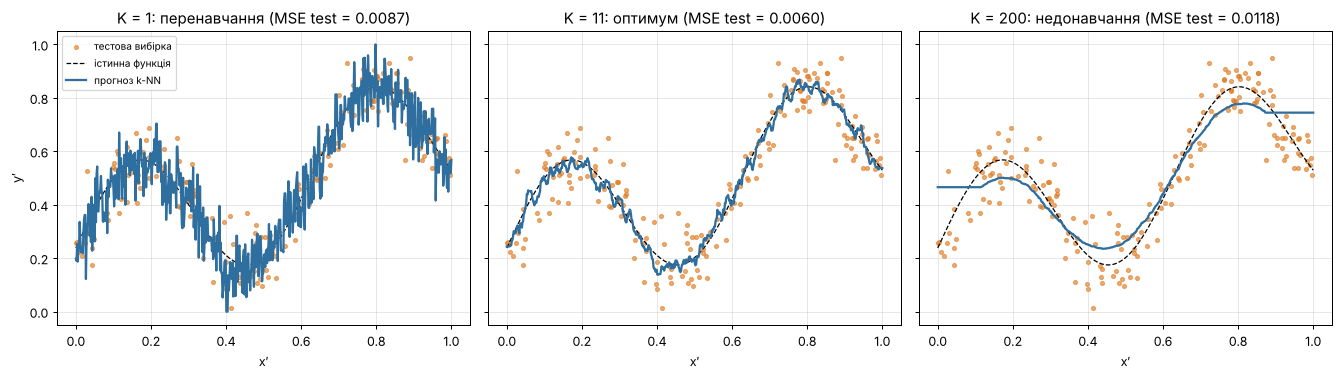

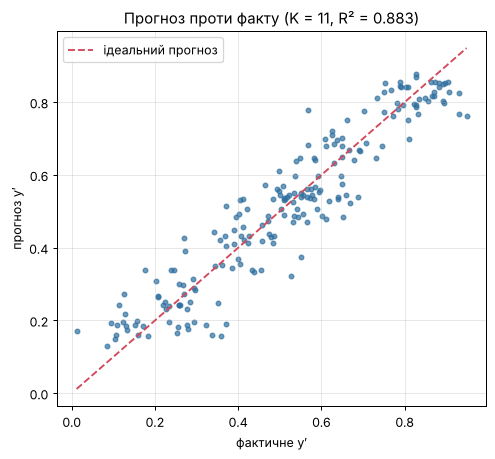

x = 2.5: прогноз y = 2.750, істинне значення без шуму = 3.045
x = 7.0: прогноз y = 5.347, істинне значення без шуму = 5.471


In [7]:
grid = np.linspace(0, 1, 600).reshape(-1, 1)
true_norm = (3 * np.sin(scaler_x.inverse_transform(grid)) + 0.5 * scaler_x.inverse_transform(grid)
             - scaler_y.data_min_[0]) / (scaler_y.data_max_[0] - scaler_y.data_min_[0])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, k, title in [(axes[0], 1, "K = 1: перенавчання"), (axes[1], best_k, f"K = {best_k}: оптимум"),
                     (axes[2], 200, "K = 200: недонавчання")]:
    m = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    ax.scatter(X_test, y_test, s=10, alpha=0.6, color="#e07a1f", label="тестова вибірка")
    ax.plot(grid, true_norm, color="black", lw=1, ls="--", label="істинна функція")
    ax.plot(grid, m.predict(grid), color="#2f6f9f", lw=1.8, label="прогноз k-NN")
    ax.set_title(f"{title} (MSE test = {results.loc[k, 'MSE test']:.4f})")
    ax.set_xlabel("x′")
axes[0].set_ylabel("y′"); axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "6_fits.png", dpi=150); plt.show()

best_model = KNeighborsRegressor(n_neighbors=best_k).fit(X_train, y_train)
pred = best_model.predict(X_test)
plt.figure(figsize=(5.6, 5.2))
plt.scatter(y_test, pred, s=14, alpha=0.7, color="#2f6f9f")
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, color="#d1495b", ls="--", label="ідеальний прогноз")
plt.xlabel("фактичне y′"); plt.ylabel("прогноз y′")
plt.title(f"Прогноз проти факту (K = {best_k}, R² = {best['R² test']:.3f})"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "6_pred_vs_true.png", dpi=150); plt.show()

# Приклад прогнозу для нової точки у вихідних одиницях
x_new = np.array([[2.5], [7.0]])
y_new = scaler_y.inverse_transform(best_model.predict(scaler_x.transform(x_new)).reshape(-1, 1)).ravel()
for xi, yi in zip(x_new.ravel(), y_new):
    print(f"x = {xi}: прогноз y = {yi:.3f}, істинне значення без шуму = {3*np.sin(xi) + 0.5*xi:.3f}")